# TV4 · LAB PHÂN LỚP — MỤC 2.2: SUPPORT VECTOR MACHINE
**Dựa trên:** `Lab - Thuat toan phan lop.pdf`, trang 7–13.

Thực hành: **Iris** (mẫu 80:20, `random_state=101`, so sánh kernel); **Digits 8×8** (`SVC(C=100,gamma=0.001)`, ma trận nhầm lẫn, report); **bài tập Diabetes**; **bài tập Animal Condition**. Có thêm kiểm định chéo và xử lý rò rỉ dữ liệu để tránh diễn giải sai.

**Cách dùng:** Iris và Digits chạy được ngay không cần CSV. Diabetes và Animal Condition phải đặt dữ liệu vào `tv4_data/` (hoặc cùng thư mục notebook). Để nhận kết quả giống số liệu nhóm, cần cùng phiên bản dữ liệu, bộ tham số và cách chia tập.

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

DATA_DIR = Path('data')
FIG_DIR = Path('tv4_figures')
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
print('Thư mục đặt CSV:', DATA_DIR.resolve())
print('Thư mục lưu hình:', FIG_DIR.resolve())

Thư mục đặt CSV: C:\Users\Admin\MLGroup\Tuan05\TTPL\data
Thư mục lưu hình: C:\Users\Admin\MLGroup\Tuan05\TTPL\tv4_figures


In [22]:
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, balanced_accuracy_score, f1_score)

In [23]:
# Có thể tải các CSV đúng theo liên kết trong hai PDF và đặt vào thư mục tv4_data/.
# Bật AUTO_DOWNLOAD = True nếu muốn thử tải từ một bản sao công khai
# (cần kết nối mạng; có thể khác phiên bản Kaggle).
AUTO_DOWNLOAD = False
SOURCE_URLS = {
    'covid': 'https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv',
    'marketing': 'https://raw.githubusercontent.com/sanathNU/Customer-Personality-Analysis/master/marketing_campaign.csv',
    'wine': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'diabetes': 'https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv',
}
LOCAL_NAMES = {
    'covid': ['covid-data.csv', 'owid-covid-data.csv'],
    'marketing': ['marketing_campaign.csv'],
    'wine': ['winequality-red.csv'],
    'diabetes': ['diabetes.csv'],
}

def get_source(name):
    # Dùng tệp upload trước, trong tv4_data/ hoặc thư mục cùng notebook
    for fname in LOCAL_NAMES[name]:
        for base in (DATA_DIR, Path('.'), Path('/content')):
            candidate = base / fname
            if candidate.is_file():
                print('Đang dùng tệp:', candidate.resolve())
                return candidate
    if not AUTO_DOWNLOAD:
        print(f'CHƯA CÓ {name.upper()}: tải {LOCAL_NAMES[name][0]} và đặt trong {DATA_DIR}.')
        return None
    # COVID CSV rất lớn; chỉ tải khi bật AUTO_DOWNLOAD có chủ đích
    from urllib.request import urlretrieve
    dest = DATA_DIR / LOCAL_NAMES[name][0]
    try:
        print('Đang tải dữ liệu nguồn mở:', name)
        urlretrieve(SOURCE_URLS[name], dest)
        print('Đã lưu:', dest)
        return dest
    except Exception as exc:
        if dest.exists():
            dest.unlink()
        print(f'Không tải được {name}: {type(exc).__name__}: {str(exc)[:150]}')
        return None

def read_separated_csv(path):
    # Tự nhận dạng dấu phẩy, dấu chấm phẩy hoặc TAB
    df = pd.read_csv(path, sep=None, engine='python', encoding='utf-8-sig')
    if df.shape[1] == 1:
        raise ValueError('Không tách được các cột CSV: hãy kiểm tra dấu phân cách và mã hóa.')
    df.columns = df.columns.str.strip()
    return df

def descriptive_table(series):
    raw = pd.to_numeric(series, errors='coerce')
    valid = raw.dropna()
    if valid.empty:
        return pd.DataFrame({'Thong_bao': ['Không có giá trị số hợp lệ']})
    q1, q2, q3 = valid.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    outlier_count = ((valid < q1 - 1.5 * iqr) | (valid > q3 + 1.5 * iqr)).sum()
    values = {
        'Số dòng': len(raw),
        'Số hợp lệ': len(valid),
        'Số thiếu / không chuyển thành số': raw.isna().sum(),
        'Mean': valid.mean(),
        'Median (Q2)': valid.median(),
        'Mode đầu tiên': valid.mode().iloc[0],
        'Variance mẫu': valid.var(ddof=1),
        'Std mẫu': valid.std(ddof=1),
        'Min': valid.min(),
        'Max': valid.max(),
        'Range': valid.max() - valid.min(),
        'Q1': q1,
        'Q2': q2,
        'Q3': q3,
        'Percentile 60': valid.quantile(0.60),
        'IQR': iqr,
        'Ngoại lai quy tắc 1,5 IQR': int(outlier_count),
    }
    return pd.DataFrame(values.items(), columns=['Chỉ số', 'Giá trị'])

## 2.2.1. Ghi nhớ lý thuyết
SVM tìm **siêu phẳng** sao cho lề (*margin*) giữa các lớp càng rộng càng tốt. **Support vectors** là những điểm quyết định vị trí ranh giới phân chia. `C` cao phạt lỗi huấn luyện mạnh; `C` nhỏ tăng regularization. `gamma` càng cao với RBF thì vùng ảnh hưởng quanh mỗi mẫu càng nhỏ. **Linear** cho ranh giới tuyến tính; **RBF/poly** mô hình hóa phi tuyến; **sigmoid** có tính chất khác và không nhất thiết tốt. **Hard margin** đòi phân tách hoàn toàn; **soft margin** chấp nhận lỗi với mức phạt. Với dữ liệu nhiều thang đo, nên dùng `StandardScaler` trong `Pipeline` sau khi chia train/test. Chọn mô hình bằng CV trên train để không dò đáp án test.

Tài liệu PDF gọi Iris là hoa *cẩm chướng* và Digits là MNIST; trên thực tế `load_iris()` là **hoa diên vĩ** và `load_digits()` gồm **ảnh 8×8**, không phải MNIST 28×28.

### B1. Iris: thực hiện đúng tỷ lệ chia 80:20, random_state=101 trong PDF

,kernel,acc_train,acc_test
0,linear,0.983333,1.000000
1,poly,0.983333,1.000000
2,rbf,0.950000,0.966667
3,sigmoid,0.350000,0.266667


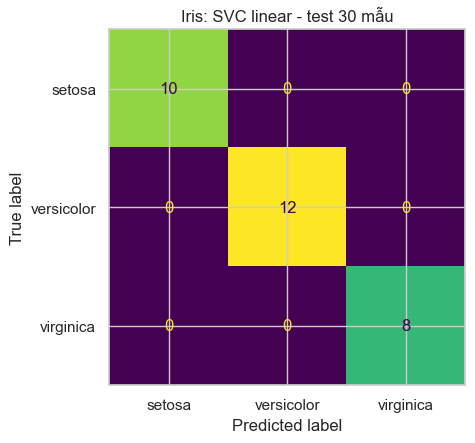

In [24]:
iris=load_iris();Xtr,Xte,ytr,yte=train_test_split(iris.data,iris.target,test_size=.2,random_state=101)
rows=[]
for k in ['linear','poly','rbf','sigmoid']:
    m=SVC(kernel=k);m.fit(Xtr,ytr)
    rows.append({'kernel':k,'acc_train':m.score(Xtr,ytr),'acc_test':m.score(Xte,yte)})
display(pd.DataFrame(rows))
model_iris=SVC(kernel='linear').fit(Xtr,ytr)
fig,ax=plt.subplots(figsize=(6,4.6))
ConfusionMatrixDisplay.from_estimator(model_iris,Xte,yte,display_labels=iris.target_names,ax=ax,colorbar=False)
ax.set_title('Iris: SVC linear - test 30 mẫu');fig.tight_layout()
fig.savefig(FIG_DIR/'svm_iris_confusion.png',dpi=150);plt.show()

**Lưu ý kiểm định:** PDF chọn kernel dựa trực tiếp trên test; đây là cách để thực tập thao tác nhưng có nguy cơ *test leakage* (thiên lệch do sử dụng test trong lựa chọn). Cell sau đánh giá CV trên train theo cùng folds khi có/không chuẩn hóa; sự cải thiện không thể khẳng định là quy luật phổ quát.

In [25]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
linear=SVC(kernel='linear')
linear_scaled=Pipeline([('scaler',StandardScaler()),('svc',SVC(kernel='linear'))])
print('CV linear không scale:',cross_val_score(linear,Xtr,ytr,cv=cv).round(4))
print('CV linear có scale:',cross_val_score(linear_scaled,Xtr,ytr,cv=cv).round(4))

CV linear không scale: [0.9167 0.9583 0.9583 1.     1.    ]
CV linear có scale: [0.9167 1.     0.9583 1.     1.    ]


### B2. Chữ số viết tay: thực hiện đúng slicing của PDF (mẫu 1500 bỏ trống)

Dữ liệu có 1.797 ảnh 8×8, mỗi ảnh biến thành vector 64 đặc trưng. Dùng `SVC(C=100, gamma=0.001)` huấn luyện `[:1500]` và kiểm tra `[1501:]` (296 mẫu), tái lập báo cáo nhóm **14 ảnh sai**.

Shape data: (1797, 64) | Image: (1797, 8, 8)
Ma trận 8x8 của ảnh đầu tiên:


,0,1,2,3,4,5,6,7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0
1,0.0,0.0,13.0,15.0,10.0,15.0,5.0,0.0
2,0.0,3.0,15.0,2.0,0.0,11.0,8.0,0.0
3,0.0,4.0,12.0,0.0,0.0,8.0,8.0,0.0
4,0.0,5.0,8.0,0.0,0.0,9.0,8.0,0.0
5,0.0,4.0,11.0,0.0,1.0,12.0,7.0,0.0
6,0.0,2.0,14.0,5.0,10.0,12.0,0.0,0.0
7,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0


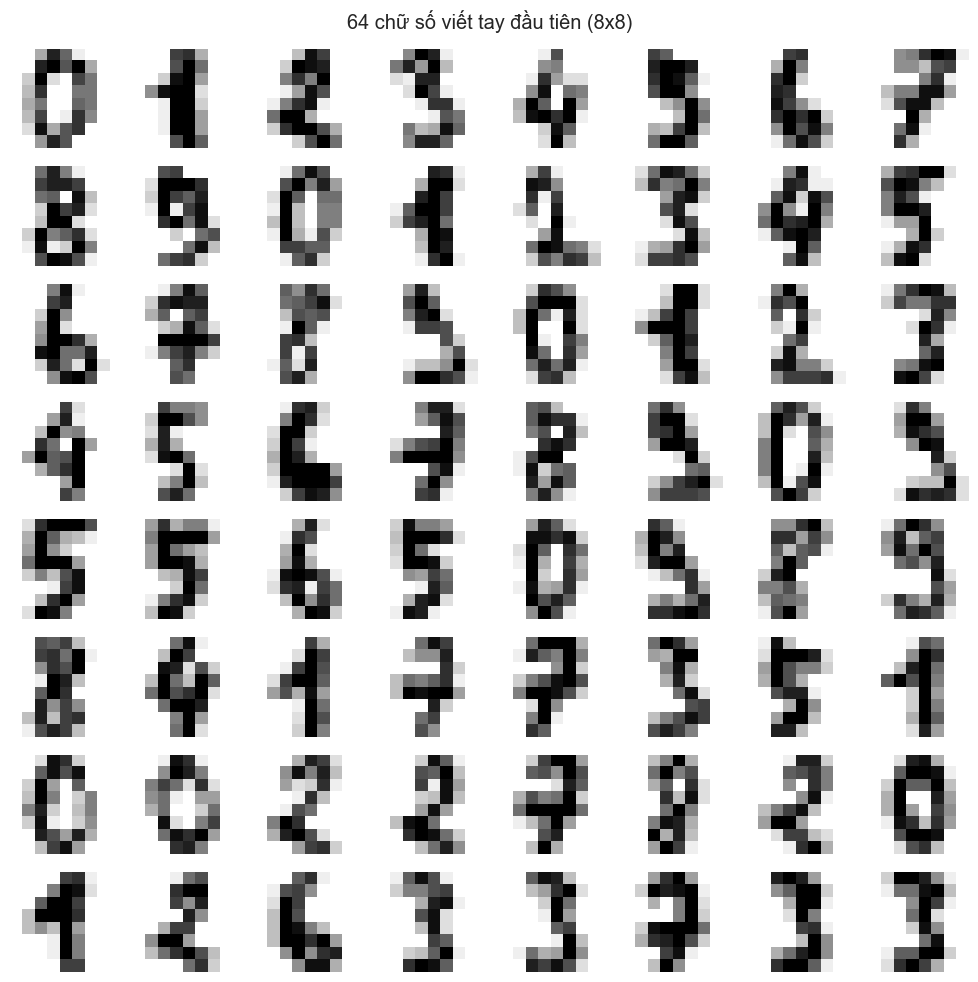

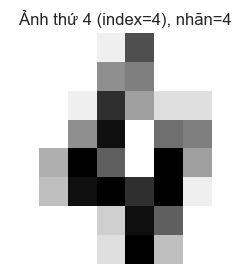

Tổng: 1797 Train: 1500 Test: 296 Bỏ qua index 1500
Accuracy: 0.9527027027027027 | số ảnh sai: 14
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        27
           1       0.94      1.00      0.97        30
           2       1.00      1.00      1.00        27
           3       1.00      0.80      0.89        30
           4       0.97      0.91      0.94        33
           5       0.91      1.00      0.95        30
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.84      0.93      0.88        28
           9       0.91      0.94      0.92        31

    accuracy                           0.95       296
   macro avg       0.96      0.95      0.95       296
weighted avg       0.96      0.95      0.95       296



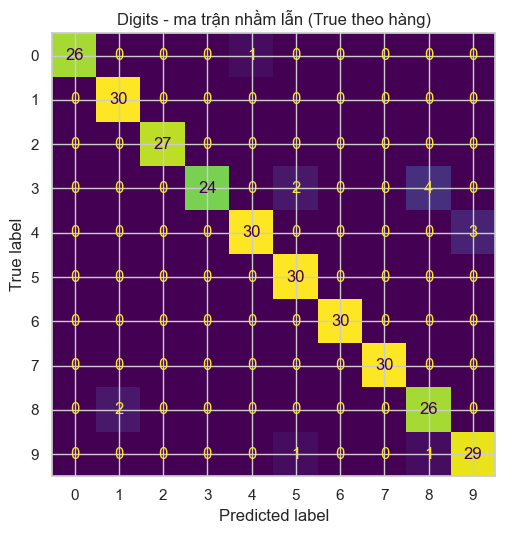

In [26]:
digits=load_digits(n_class=10)
# Nhiệm vụ 1: xem dữ liệu ảnh chữ số và 64 ảnh đầu
print('Shape data:', digits.data.shape, '| Image:', digits.images.shape)
print('Ma trận 8x8 của ảnh đầu tiên:')
display(pd.DataFrame(digits.images[0]))
fig, axs = plt.subplots(8,8,figsize=(10,10))
for i,ax in enumerate(axs.flat):
    ax.imshow(digits.images[i],cmap='binary')
    ax.axis('off')
fig.suptitle('64 chữ số viết tay đầu tiên (8x8)')
fig.tight_layout()
fig.savefig(FIG_DIR/'svm_digits_64_examples.png',dpi=150)
plt.show()
plt.figure(figsize=(3,3))
plt.imshow(digits.images[4],cmap='gray_r')
plt.title(f'Ảnh thứ 4 (index=4), nhãn={digits.target[4]}')
plt.axis('off')
plt.show()

X,y=digits.data,digits.target
svc=SVC(gamma=.001,C=100).fit(X[:1500],y[:1500])
y_true=y[1501:];y_pred=svc.predict(X[1501:])
print('Tổng:',len(X),'Train:',1500,'Test:',len(y_true),'Bỏ qua index 1500')
print('Accuracy:',accuracy_score(y_true,y_pred),'| số ảnh sai:',(y_true!=y_pred).sum())
print(classification_report(y_true,y_pred,zero_division=0))
fig,ax=plt.subplots(figsize=(7,5.5))
ConfusionMatrixDisplay.from_predictions(y_true,y_pred,ax=ax,colorbar=False)
ax.set_title('Digits - ma trận nhầm lẫn (True theo hàng)')
fig.tight_layout();fig.savefig(FIG_DIR/'svm_digits_confusion.png',dpi=150);plt.show()

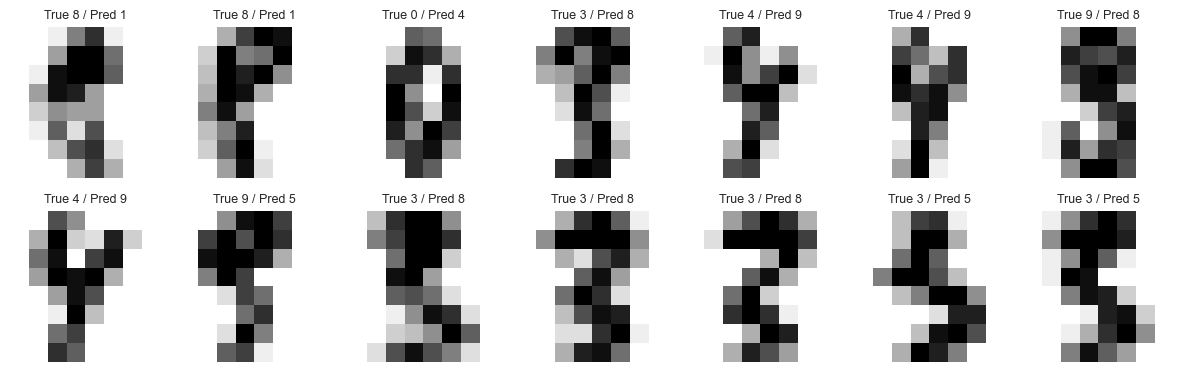

In [27]:
err=np.flatnonzero(y_true!=y_pred)
fig,axes=plt.subplots(2,7,figsize=(12,4))
for ax,j in zip(axes.ravel(),err):
    ax.imshow(digits.images[1501+j],cmap='gray_r')
    ax.set_title(f'True {y_true[j]} / Pred {y_pred[j]}',fontsize=9)
    ax.axis('off')
fig.tight_layout();fig.savefig(FIG_DIR/'svm_digits_errors.png',dpi=150);plt.show()

### B3. Tối ưu SVM Digits không dùng test để chọn tham số

Tìm kiếm `C=[1,10,100]`, `gamma=[.0001,.001,.01]` trên 1.500 ảnh train với 5-fold Stratified CV. Các con số có thể khác cấu hình, seed, lưới tham số trong notebook nhóm; do đó phải nêu rõ cài đặt thay vì cố ép ra `C=10`.

In [28]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
grid=GridSearchCV(SVC(),{'kernel':['rbf'],'C':[1,10,100],
                         'gamma':[.0001,.001,.01]},cv=cv,scoring='accuracy',n_jobs=1)
grid.fit(X[:1500],y[:1500]);print('Tham số:',grid.best_params_)
print('Điểm CV tốt nhất:',grid.best_score_)
print('Điểm holdout:',grid.score(X[1501:],y[1501:]))

Tham số: {'C': 1, 'gamma': 0.001, 'kernel': 'rbf'}
Điểm CV tốt nhất: 0.9913333333333334
Điểm holdout: 0.9527027027027027


### B4. SVM Diabetes: tiền xử lý không rò rỉ dữ liệu

Tất cả bước điền missing và chuẩn hóa đều nằm trong `Pipeline` (fit bằng train), tránh tính median/mean từ test. Chia 80:20 có `stratify=y`. Báo cáo nhóm cho biết accuracy **0,71**, nhưng không có CSV/notebook gốc nên không cam kết chạy ra đúng con số nếu seed và xử lý khác.

Đang dùng tệp: C:\Users\Admin\MLGroup\Tuan05\TTPL\data\diabetes.csv
Bộ Pima: (768, 9) ; Nhãn: {0: 500, 1: 268}
Best: {'svm__C': 1, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'} | CV F1: 0.676112893721637
Test acc: 0.7402597402597403 | balanced acc: 0.7361111111111112
              precision    recall  f1-score   support

           0       0.83      0.75      0.79       100
           1       0.61      0.72      0.66        54

    accuracy                           0.74       154
   macro avg       0.72      0.74      0.73       154
weighted avg       0.75      0.74      0.74       154



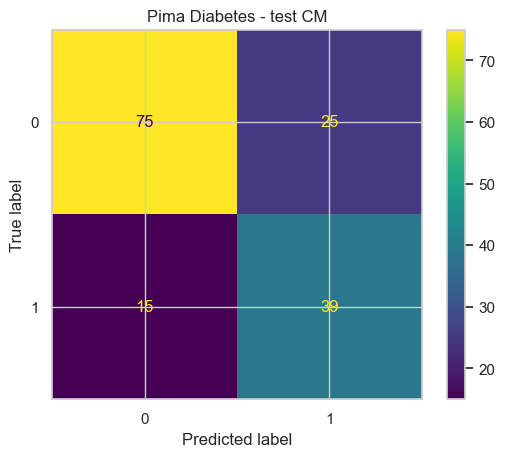

In [29]:
path = get_source('diabetes')
if path is not None:
    pima = read_separated_csv(path)
    if 'Outcome' not in pima.columns:
        raise ValueError('Không có cột Outcome trong diabetes.csv!')
    print('Bộ Pima:', pima.shape, '; Nhãn:',pima['Outcome'].value_counts().to_dict())

if 'pima' in globals():
    Xd=pima.drop(columns='Outcome').copy();yd=pima['Outcome'].copy()
    for c in ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']:
        Xd[c]=Xd[c].replace(0,np.nan)
    A,B,ya,yb=train_test_split(Xd,yd,test_size=.2,stratify=yd,random_state=42)
    pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),
                   ('scaler',StandardScaler()),('svm',SVC(class_weight='balanced'))])
    search=GridSearchCV(pipe,{'svm__C':[.1,1,10,100],
                              'svm__gamma':['scale',.001,.01,.1],
                              'svm__kernel':['rbf']},cv=5,scoring='f1',n_jobs=1)
    search.fit(A,ya);p=search.predict(B)
    print('Best:',search.best_params_,'| CV F1:',search.best_score_)
    print('Test acc:',accuracy_score(yb,p),'| balanced acc:',balanced_accuracy_score(yb,p))
    print(classification_report(yb,p,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(yb,p);plt.title('Pima Diabetes - test CM')
    plt.savefig(FIG_DIR/'svm_diabetes_confusion.png',dpi=150);plt.show()
else: print('Chưa chạy: chưa có Pima CSV. Hãy tải dữ liệu và chạy lại từ đầu.')

### B5. SVM Animal Condition: bài tập dữ liệu động vật

Tải CSV từ nguồn Kaggle của bài 2.2.4 và đặt trong `tv4_data/animal_condition.csv`, cột nhãn thường là `Dangerous`. Tên cột có thể khác theo phiên bản; cell dưới liệt kê cột, tìm `dangerous/condition/target/label` và yêu cầu xác nhận. Mô hình mã hóa biến danh mục bằng OneHotEncoder, điền missing trong Pipeline, đo **recall/F1 lớp thiểu số** bên cạnh accuracy; không khẳng định 1,00 có nghĩa là mô hình tốt.

In [30]:
animal_file=DATA_DIR/'animal.csv'
if animal_file.exists():
    animal=read_separated_csv(animal_file)
    animal.columns=animal.columns.str.strip()
    print('Animal shape:',animal.shape,'columns:',animal.columns.tolist())
    candidates=[c for c in animal.columns if c.lower().strip() in {'dangerous','condition','target','label','outcome'}]
    if not candidates:
        print('Không rõ cột nhãn. Hãy tự đặt target_col thành cột nhãn đúng trong danh sách ở trên.')
    else:
        target_col=candidates[0];print('Đang dùng cột nhãn:',target_col)
        animal=animal.dropna(subset=[target_col]).copy()
        print('Phân bố lớp:',animal[target_col].value_counts().to_dict())
        Xa=animal.drop(columns=[target_col]);ya=animal[target_col]
        num=Xa.select_dtypes(include='number').columns.tolist()
        cat=[c for c in Xa.columns if c not in num]
        prep=ColumnTransformer([
           ('num',Pipeline([('imp',SimpleImputer(strategy='median')),
                            ('scale',StandardScaler())]),num),
           ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),
                            ('ohe',OneHotEncoder(handle_unknown='ignore'))]),cat)])
        if ya.value_counts().min() >= 2:
            A,B,yt,ys=train_test_split(Xa,ya,test_size=.2,random_state=42,stratify=ya)
            model=Pipeline([('prep',prep),('svc',SVC(C=1,kernel='rbf',class_weight='balanced'))])
            model.fit(A,yt);p=model.predict(B)
            print('Accuracy:',accuracy_score(ys,p),'Balanced accuracy:',balanced_accuracy_score(ys,p))
            print(classification_report(ys,p,zero_division=0))
            print('Ma trận nhầm lẫn; hàng=nhãn thật, cột=nhãn dự đoán:')
            print(confusion_matrix(ys,p,labels=sorted(ya.unique())))
        else: print('Lớp quá ít mẫu để chia train/test stratified.')
else: print('CHƯA CÓ dữ liệu động vật: tải CSV vào',animal_file)

Animal shape: (871, 7) columns: ['AnimalName', 'symptoms1', 'symptoms2', 'symptoms3', 'symptoms4', 'symptoms5', 'Dangerous']
Đang dùng cột nhãn: Dangerous
Phân bố lớp: {'Yes': 849, 'No': 20}
Accuracy: 1.0 Balanced accuracy: 1.0
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         4
         Yes       1.00      1.00      1.00       170

    accuracy                           1.00       174
   macro avg       1.00      1.00      1.00       174
weighted avg       1.00      1.00      1.00       174

Ma trận nhầm lẫn; hàng=nhãn thật, cột=nhãn dự đoán:
[[  4   0]
 [  0 170]]


## Kết luận thực hành cần ghi trong báo cáo
- Theo cách chia nguyên gốc PDF: Iris SVC kernel `linear` **30/30 đúng = 100%**; Digits SVC (`C=100`, `gamma=0.001`) **282/296 đúng = 95,27%**, có **14 ảnh sai**. Đó là kết quả của cấu hình **cụ thể**, không chứng minh mô hình luôn hoàn hảo.
- Tài liệu nhóm nêu Diabetes accuracy khoảng **0,71**, Animal accuracy **1,00**; đây là **số liệu nhóm cung cấp**, không phải kết quả notebook tính được nếu chưa tải CSV. Với lớp mất cân bằng, nhớ ghi recall/F1/balanced accuracy và ma trận nhầm lẫn.
- GridSearchCV có thể tìm ra `C` khác bản nhóm; việc khác nhau phụ thuộc seed, folds, lưới giá trị và tiền xử lý. Luôn ghi cấu hình tìm kiếm.